# Run AMP Algorithm with proximal denoisers

In [1]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)

p = 600
L = 2 # num signals. L-1 changepoints

δ_list = [8.0, 8.5]

# chgpt_locations = np.array([0.3, 0.7])
chgpt_locations = np.array([0.5])

Σ = np.zeros((p, p))
for i in range(p):
    for j in range(p):
        Σ[i, j] = 0.5 ** (np.abs(i - j))
L_chol = scipy.linalg.cholesky(Σ, lower = True)

def ℓ(Θ, y):
    return ζ(Θ) - y * Θ

# def ℓ(Θ, y):
#     return jnp.power(y - Θ, 2)

lasso_corr_list = [[] for ℓ_ in range(L)]
amp_corr_list = [[] for ℓ_ in range(L)]
comparison_corr_list = [[] for ℓ_ in range(L)]
comparison_MSE_list = [[] for ℓ_ in range(L)]

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
        print("C_true.shape: ", C_true.shape)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int)

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/100)
    Lmin = 2
    Lmax = 2
    # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Gaussian Signal Prior
    κ = 0.25
    B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)

    # Generate the observation vector Y
    # X = np.random.normal(0, np.sqrt(1/n), (n, p)) @ L_chol.T
    X = np.random.normal(0, np.sqrt(1/n), (n, p))

    # scaler = StandardScaler().fit(X)
    # X = scaler.transform(X)
    Θ = X @ B̃
    y = logistic_reg(Θ, C_true).astype(np.float64).flatten()
    # y = lin_reg(Θ, C_true).astype(np.float64).flatten()

    # For debugging, try also just standard logistic regression, so when ϕ is just uniform, and only one true signal produced. 
    # --- Run Weighted ERM and AMP --- #
    B̂ = np.zeros((p, L))
    for ℓ_ in range(L):
        β̂_amp, θ̂_amp = WERM.amp(X, y, n, p, ϕ[ℓ_, :].flatten(), ℓ, max_iter = 10) # Seems stable for small iterations, see if that performs almost as well as the optimization. Then, try to find bugs and scale up the AMP in terms of number of iters. 
        amp_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp, B̃[:, ℓ_]))

        print("Regressing on signal ", ℓ_)
        sample_weight = ϕ[ℓ_, :]
        # Weight data for \beta^1, ϕ is L × n
        # logistic_reg_CV = linear_model.LogisticRegressionCV(cv=5, n_jobs = 2, penalty = 'l2', max_iter=int(1e5))
        # logistic_reg_CV.fit(X, Y.flatten(), sample_weight = sample_weight)
        # print("C_: ", logistic_reg_CV.C_)
        # logistic_reg = linear_model.LogisticRegression(C=logistic_reg_CV.C_[0], n_jobs = 2, penalty = 'l2', max_iter=int(1e5))

        sk_logistic_reg = linear_model.LogisticRegression(n_jobs = 2, max_iter=int(1e5), penalty = None)
        sk_logistic_reg.fit(X, y, sample_weight = sample_weight)
        β̂ = sk_logistic_reg.coef_

        # sk_lin_reg = linear_model.LinearRegression(n_jobs = 2)
        # sk_lin_reg.fit(X, y, sample_weight = sample_weight)
        # β̂ = sk_lin_reg.coef_

        B̂[:, ℓ_] = β̂
        lasso_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))

        comparison_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp.flatten(), β̂.flatten()))
        comparison_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), β̂.flatten()))

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
# Sqcorr plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, lasso_corr_list[ℓ_], label="β" + str(ℓ_), marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, amp_corr_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="-.", c=PAL[ℓ_], alpha = 0.5)
    plt.errorbar(δ_list, comparison_corr_list[ℓ_], label="β" + str(ℓ_) + " comp", marker="D", ls="--", c=PAL[ℓ_], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, comparison_MSE_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="D", ls="--", c=PAL[ℓ_], alpha = 1.0)
# plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()

  0%|          | 0/2 [00:00<?, ?it/s]

δ =  9.0
C_true.shape:  (5400,)


  0%|          | 0/10 [00:00<?, ?it/s]

θ_test args:  -0.016210881874161642 1.0 0.5 1.0
θ_test:  0.20789681444330632
c:  -0.11221708205856216
θ_test args:  0.06576390811820704 1.0 0.9901443619174309 1.0
θ_test:  0.45104640286664216
c:  -0.09569415932807426
θ_test args:  0.9603396456768002 1.0 1.161106507348917 1.0
θ_test:  1.2241508744968463
c:  -0.09303851393414297
θ_test args:  0.9426733087602321 1.0 1.194248558073066 1.0
θ_test:  1.2157750338801607


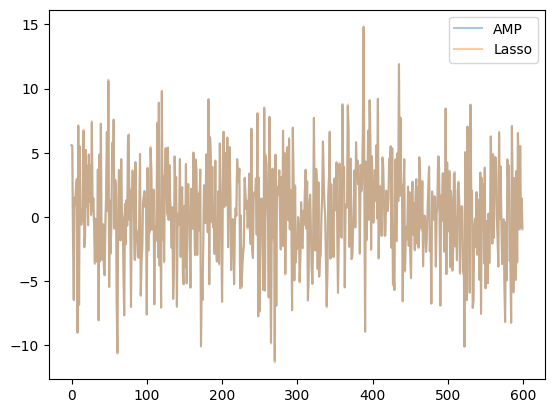

In [2]:
plt.plot(β̂_amp.flatten(), label="AMP", alpha = 0.4)
plt.plot(β̂.flatten(), label="Lasso", alpha = 0.4)
plt.legend()
plt.show()

In [3]:
plt.plot(ϕ.T)

DeviceArray(0.25, dtype=float64, weak_type=True)